# Lab — Week 2: the math toolkit in NumPy (and a first taste of pandas)
**Introduction to AI · L3 · Week 2 · 90 minutes · pairs**

Everything you computed by hand in the lecture, now in Python. For each **TODO**, write the code, then check your result against the number given in the comment.

| Part | Topic | Minutes |
| --- | --- | --- |
| 1 | NumPy arrays, shapes, vectorisation | 15 |
| 2 | Vectors: dot product, norms, distances, cosine | 15 |
| 3 | Matrices: predictions for every row with `X @ theta` | 15 |
| 4 | Derivatives and gradient descent | 20 |
| 5 | Statistics and Bayes by simulation | 15 |
| 6 | pandas in 10 minutes | 10 |

## Part 1 — Arrays, shapes and why loops are slow

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import time

a = np.array([2, 1, 3])
print("a       :", a, "| shape:", a.shape, "| dtype:", a.dtype)

M = np.array([[1, 2], [3, 0], [2, 5]])
print("M shape :", M.shape)          # (rows, columns)
print("row 0   :", M[0])
print("column 1:", M[:, 1])
print("M.T     :\n", M.T, "| shape:", M.T.shape)

a       : [2 1 3] | shape: (3,) | dtype: int64
M shape : (3, 2)
row 0   : [1 2]
column 1: [2 0 5]
M.T     :
 [[1 3 2]
 [2 0 5]] | shape: (2, 3)


**Vectorisation:** NumPy applies an operation to a whole array at once, in fast compiled code. Compare a Python loop with NumPy on one million numbers.

In [33]:
x = np.random.default_rng(0).random(1_000_000)
w = np.random.default_rng(1).random(1_000_000)

t0 = time.perf_counter()
total = 0.0
for i in range(len(x)):
    total += x[i] * w[i]
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
total_np = x @ w
t_np = time.perf_counter() - t0

print(f"loop : {total:.4f}  in {t_loop:.3f} s")
print(f"numpy: {total_np:.4f}  in {t_np:.5f} s   ->  about {t_loop / t_np:.0f}x faster")

loop : 250247.1565  in 0.238 s
numpy: 250247.1565  in 0.01429 s   ->  about 17x faster


**Broadcasting:** NumPy stretches smaller arrays to match bigger ones. Predict each output before running.

In [34]:
X = np.array([[120, 3], [85, 2], [200, 5]], dtype=float)
print(X - X.mean(axis=0))   # subtract the mean of each column from every row
print(X * np.array([0.5, 10]))  # scale each column differently

[[-15.          -0.33333333]
 [-50.          -1.33333333]
 [ 65.           1.66666667]]
[[ 60.   30. ]
 [ 42.5  20. ]
 [100.   50. ]]


**Question:** what does `axis=0` mean in `X.mean(axis=0)`? What would `axis=1` give?

Axis=0: calculates the average down each column and gives you one value per column
Axis=1: calculates the average across each row giving you one value per row

## Part 2 — Vectors (check the lecture exercise)

In [35]:
a = np.array([2, 1, 3])
b = np.array([1, 4, -1])

def dot_loop(u, v):
    # TODO: compute the dot product with a for-loop (no NumPy functions)
    s = 0
    if (len(u)==len(v)):
        n=len(u)
        for i in range(n):
            s += u[i] * v[i]
    else :
        print("ERROR !! INVALID OPERATION")
    return s
print("a + b      :", a + b)            # expect [3 5 2]
print("3a         :", 3 * a)            # expect [6 3 9]
print("dot (loop) :", dot_loop(a, b))   # expect 3
print("dot (numpy):", a @ b)            # expect 3

a + b      : [3 5 2]
3a         : [6 3 9]
dot (loop) : 3
dot (numpy): 3


In [36]:
# TODO: complete the three functions using only basic NumPy (np.sqrt, np.abs, np.sum)
def l2(v):
    v_sqrt=v**2
    vs=np.sum(v_sqrt)
    N2=np.sqrt(vs)
    return N2

def l1(v):
    v_abs=np.abs(v)
    N1=np.sum(v_abs)
    return N1

def cosine(u, v):
    p=dot_loop(u,v)
    un=l2(u)
    vn=l2(v)
    puv=un*vn
    cos=p/puv
    return cos

print("Euclidean distance ||a - b||_2:", round(l2(a - b), 3))   # expect 5.099
print("Manhattan distance ||a - b||_1:", l1(a - b))             # expect 8
print("cosine(a, b)                  :", round(cosine(a, b), 3))  # expect 0.189
print("check with np.linalg.norm     :", round(np.linalg.norm(a - b), 3))

Euclidean distance ||a - b||_2: 5.099
Manhattan distance ||a - b||_1: 8
cosine(a, b)                  : 0.189
check with np.linalg.norm     : 5.099


**The scaling trap.** Two houses differ by 20 m² in area and by 13 km in distance from the centre. Which difference dominates the Euclidean distance? Run the cell, then fix it with z-scores (Part 5 formula).

In [37]:
houses = np.array([[100, 2.0],    # area m², distance km
                   [120, 15.0],
                   [102, 2.5]])
print("distance house0-house1:", round(l2(houses[0] - houses[1]), 2))
print("distance house0-house2:", round(l2(houses[0] - houses[2]), 2))

# TODO: standardise each column: z = (x - mean) / std, then recompute both distances

n = len(houses)
s = np.sum(houses, axis=0)
mean = s / n
l = houses - mean
l_sqrt = l ** 2
l_s = np.sum(l_sqrt, axis=0)
v = l_s / n  
std = np.sqrt(v)
Z = l / std

print("after scaling 0-1:", round(l2(Z[0] - Z[1]), 2), "| 0-2:", round(l2(Z[0] - Z[2]), 2))

distance house0-house1: 23.85
distance house0-house2: 2.06
after scaling 0-1: 3.1 | 0-2: 0.24


**Question:** which house is the 'nearest neighbour' of house 0 before and after scaling? Why does this matter for k-NN?

The nearest house to House 0 before and after scaling is House 2
It matters because feature scaling prevents variables with large numerical ranges from dominating calculations over features with small units (expl : m² , km)

## Part 3 — Matrices: predictions for every row at once

In [38]:
X = np.array([[1, 2],
              [3, 0],
              [2, 5]])
theta = np.array([0.5, 2])

y_hat = X @ theta
print("predictions:", y_hat)      # expect [4.5 1.5 11.]
print("shapes     :", X.shape, "@", theta.shape, "->", y_hat.shape)

predictions: [ 4.5  1.5 11. ]
shapes     : (3, 2) @ (2,) -> (3,)


In [39]:
# Shape errors are the most common bug in ML code. Read this message carefully.
try:
    np.ones((100, 4)) @ np.ones(3)
except ValueError as e:
    print("ValueError:", e)

# TODO: predict the output shape BEFORE running each line, then run
A = np.ones((2, 3)); B = np.ones((3, 5))
print((A @ B).shape)
Xbig = np.ones((100, 4))
print((Xbig.T @ Xbig).shape)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 4)
(2, 5)
(4, 4)


The prediction :
 A.B = (2,5)
 Xt.X = (4,4)

**Preview of week 5 — the normal equation.** For a linear model with a column of ones (the bias), the best parameters are θ = (XᵀX)⁻¹ Xᵀ y. Here we fit `time = θ₀ + θ₁ × distance` to last week's 3 deliveries.

In [40]:
distance = np.array([2.0, 4.0, 6.0])
time_min = np.array([10.0, 18.0, 26.0])

Xb = np.c_[np.ones(3), distance]          # add the column of ones -> shape (3, 2)
theta_best = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ time_min
print("theta_0, theta_1 =", theta_best.round(3))   # expect [2. 4.]  ->  time = 2 + 4 x distance

theta_0, theta_1 = [2. 4.]


## Part 4 — Derivatives and gradient descent

In [41]:
f = lambda w: (w - 3) ** 2
f_prime = lambda w: 2 * (w - 3)

# A numerical derivative: the slope between two very close points
def numerical_derivative(func, w, h=1e-5):
    return (func(w + h) - func(w - h)) / (2 * h)

for w in [0, 3, 5]:
    print(f"w={w}: formula {f_prime(w):+.4f} | numerical {numerical_derivative(f, w):+.4f}")

w=0: formula -6.0000 | numerical -6.0000
w=3: formula +0.0000 | numerical +0.0000
w=5: formula +4.0000 | numerical +4.0000


The two columns agree: this 'gradient check' is how deep-learning libraries are tested. Now run gradient descent.

eta=0.1, first steps: [0.    0.6   1.08  1.464]
eta=1.1, first steps: [ 0.     6.6   -1.32   8.184]
eta=0.5:  [0. 3. 3. 3.]
eta=0.9:  [0.    5.4   1.08  4.536]
eta=1.0:  [0. 6. 0. 6.]


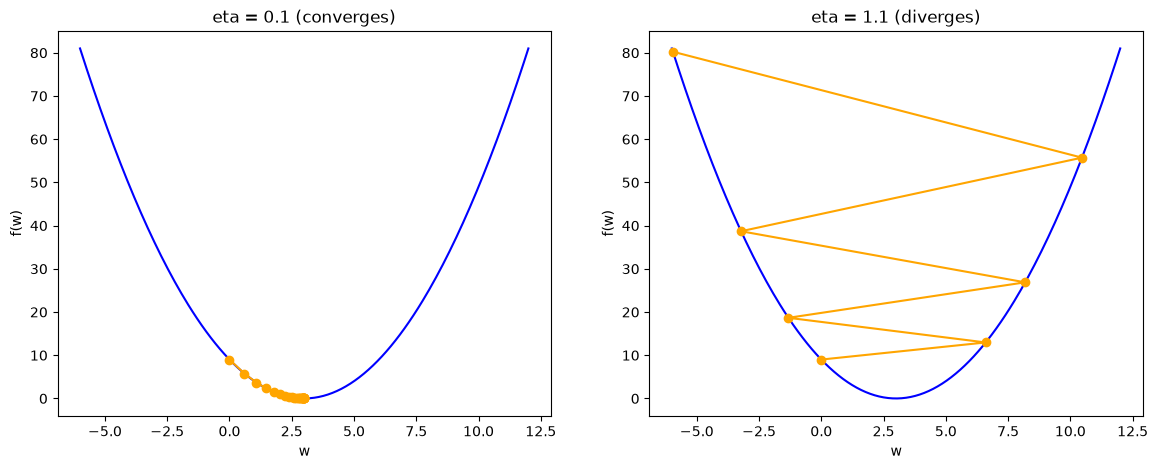

In [42]:
def gradient_descent(w0, eta, steps):
    path = [w0]
    w = w0
    for _ in range(steps):
        w = w - eta * f_prime(w)     # the update rule from the lecture
        path.append(w)
    return np.array(path)

path_good = gradient_descent(0.0, eta=0.1, steps=25)
path_bad = gradient_descent(0.0, eta=1.1, steps=6)
eta05 = gradient_descent(0.0, eta=0.5, steps=6)
eta09 = gradient_descent(0.0, eta=0.9, steps=6)
eta10 = gradient_descent(0.0, eta=1.0, steps=6)


print("eta=0.1, first steps:", path_good[:4].round(3))   # expect [0. 0.6 1.08 1.464]
print("eta=1.1, first steps:", path_bad[:4].round(3))    # expect [0. 6.6 -1.32 8.184]
print("eta=0.5: ", eta05[:4].round(3))
print("eta=0.9: ", eta09[:4].round(3))
print("eta=1.0: ", eta10[:4].round(3))

ws = np.linspace(-6, 12, 200)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, path, title in zip(axes, [path_good, path_bad], ["eta = 0.1 (converges)", "eta = 1.1 (diverges)"]):
    ax.plot(ws, f(ws), "b-")
    ax.plot(path, f(path), "o-", color="orange")
    ax.set_title(title); ax.set_xlabel("w"); ax.set_ylabel("f(w)")
plt.show()

What happens : 
eta=0.5: It reaches the minimum in one step
eta=0.9: Converges but swings while approaching it
eta=1.0 : It diverges (swings between 0 and 6 and never converging)

The fastest value : eta=0.5 , because : o<- 0-0.5*(-6) = 3 , and it's always 3 after this

**TODO:** try `eta = 0.5`, `eta = 0.9` and `eta = 1.0`. Describe what happens in each case. Which value is fastest? (Hint: for this function, η = 0.5 jumps to the minimum in one step — why?)

**Two parameters.** Gradient descent on f(w₁, w₂) = w₁² + 3w₂², whose gradient is [2w₁, 6w₂].

final theta: [0.005 0.   ]


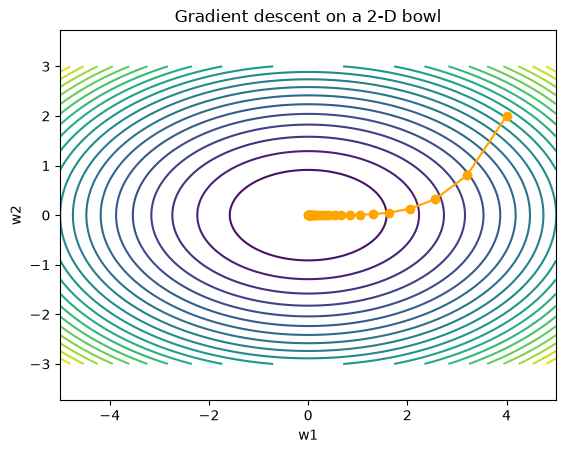

In [43]:
theta = np.array([4.0, 2.0])
eta = 0.1
trajectory = [theta.copy()]
for _ in range(30):
    grad = np.array([2 * theta[0], 6 * theta[1]])   # TODO: check this gradient by hand
    theta = theta - eta * grad
    trajectory.append(theta.copy())
trajectory = np.array(trajectory)
print("final theta:", trajectory[-1].round(4))       # close to [0, 0]

g1, g2 = np.meshgrid(np.linspace(-5, 5, 100), np.linspace(-3, 3, 100))
plt.contour(g1, g2, g1 ** 2 + 3 * g2 ** 2, levels=20)
plt.plot(trajectory[:, 0], trajectory[:, 1], "o-", color="orange")
plt.xlabel("w1"); plt.ylabel("w2"); plt.title("Gradient descent on a 2-D bowl"); plt.axis("equal"); plt.show()

**Question:** why does the path move faster along w₂ at the start? (Look at the gradient formula.)

The gradient : CHECKED 
w2 moves faster at the start because its gradient has a larger magnitude , w1=2*4=8 < 12 = 6*2 =w2

## Part 5 — Statistics and Bayes by simulation

In [44]:
grades = np.array([8, 10, 11, 12, 19])
print("mean    :", grades.mean())            # expect 12.0
print("median  :", np.median(grades))        # expect 11.0
print("var (n) :", grades.var())             # expect 14.0  (divides by n)
print("var(n-1):", grades.var(ddof=1))       # expect 17.5  (divides by n-1, like pandas)
print("std     :", round(grades.std(), 3))   # expect 3.742
z = (grades - grades.mean()) / grades.std()
print("z-scores:", z.round(2))

mean    : 12.0
median  : 11.0
var (n) : 14.0
var(n-1): 17.5
std     : 3.742
z-scores: [-1.07 -0.53 -0.27  0.    1.87]


**Bayes by counting.** Simulate one million people: 1% sick, the test detects 90% of sick people, and gives a false positive for 5% of healthy people. Among the positives, what fraction is really sick?

In [45]:
rng = np.random.default_rng(42)
n = 1_000_000
sick = rng.random(n) < 0.20
positive = np.where(sick, rng.random(n) < 0.90, rng.random(n) < 0.05)

# TODO: compute P(sick | positive) by counting
p_sick_given_pos =np.mean( sick[positive])   # hint: sick[positive] keeps only the people who tested positive
print(f"P(sick | positive) ≈ {p_sick_given_pos:.3f}")    # expect about 0.154
print("Bayes formula      =", round(0.9 * 0.01 / (0.9 * 0.01 + 0.05 * 0.99), 3))

P(sick | positive) ≈ 0.817
Bayes formula      = 0.154


WHat happens :
 P(sick|positive) increases from about 0.154 to 0.817 because when the rate of sickness increases a positive test is more likely to be true positive rather than false positive

**TODO:** change the disease rate from 1% to 20% and run again. What happens to P(sick | positive)? Explain in one sentence why the base rate matters so much.

**Correlation is not causation.** In this simulated city, temperature drives both ice-cream sales and swimming accidents.

correlation(ice cream, accidents) = 0.75


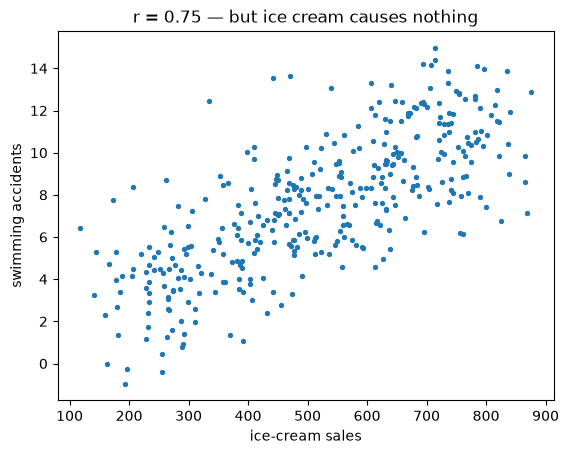

In [46]:
temperature = rng.uniform(10, 40, 365)
ice_cream = 20 * temperature + rng.normal(0, 60, 365)
accidents = 0.3 * temperature + rng.normal(0, 2, 365)
r = np.corrcoef(ice_cream, accidents)[0, 1]
print(f"correlation(ice cream, accidents) = {r:.2f}")
plt.scatter(ice_cream, accidents, s=8); plt.xlabel("ice-cream sales"); plt.ylabel("swimming accidents")
plt.title(f"r = {r:.2f} — but ice cream causes nothing"); plt.show()

## Part 6 — pandas in 10 minutes
pandas is NumPy with column names. Every lab from now on starts with a pandas DataFrame. The data below is **fictional**, generated for practice.

In [47]:
import pandas as pd

rng = np.random.default_rng(7)
n = 120
df = pd.DataFrame({
    "attendance_pct": rng.integers(40, 101, n),
    "study_hours_week": rng.normal(6, 3, n).clip(0).round(1),
    "city": rng.choice(["Algiers", "Oran", "Constantine", "Annaba"], n),
})
df["final_grade"] = (2 + 0.08 * df["attendance_pct"] + 0.6 * df["study_hours_week"] + rng.normal(0, 1.5, n)).clip(0, 20).round(1)
df.loc[rng.choice(n, 6, replace=False), "study_hours_week"] = np.nan   # some missing values

df.head()

,attendance_pct,study_hours_week,city,final_grade
0,97,4.0,Constantine,10.0
1,78,6.6,Annaba,11.5
2,81,4.6,Annaba,12.4
3,94,6.4,Constantine,13.2
4,75,2.4,Annaba,9.6


In [48]:
print(df.shape)
print(df.isna().sum())          # missing values per column
df.describe()

(120, 4)
attendance_pct      0
study_hours_week    6
city                0
final_grade         0
dtype: int64


,attendance_pct,study_hours_week,final_grade
count,120.000000,114.000000,120.000000
mean,71.433333,5.568421,10.980833
std,17.375600,2.655611,2.653056
min,40.000000,0.000000,5.800000
25%,56.750000,3.925000,9.075000
50%,71.000000,5.500000,10.650000
75%,87.250000,7.325000,12.600000
max,100.000000,12.700000,17.700000


In [49]:
# Filtering, grouping, new columns
print("students with attendance < 60%:", (df["attendance_pct"] < 60).sum())
print(df.groupby("city")["final_grade"].agg(["mean", "count"]).round(2))
df["passed"] = df["final_grade"] >= 10
print("pass rate:", df["passed"].mean().round(3))
print(df[["attendance_pct", "study_hours_week", "final_grade"]].corr().round(2))

students with attendance < 60%: 34
              mean  count
city                     
Algiers      10.53     34
Annaba       10.79     30
Constantine  11.61     27
Oran         11.12     29
pass rate: 0.625
                  attendance_pct  study_hours_week  final_grade
attendance_pct              1.00              0.05         0.62
study_hours_week            0.05              1.00         0.62
final_grade                 0.62              0.62         1.00


**TODOs:**
1. What is the mean final grade of students who study more than 8 hours a week?
2. Fill the missing `study_hours_week` values with the **median**, then check that `df.isna().sum()` is all zeros.
3. Plot `final_grade` against `attendance_pct` with `df.plot.scatter(...)`.
4. Compute P(passed | attendance ≥ 80%) and P(passed). Are passing and attendance independent in this data?

13.57
attendance_pct      0
study_hours_week    0
city                0
final_grade         0
passed              0
dtype: int64
 Calcule results : 
 P(passed|attendance>= 80%):  0.857
 P(passed):  0.625
 Independent: False


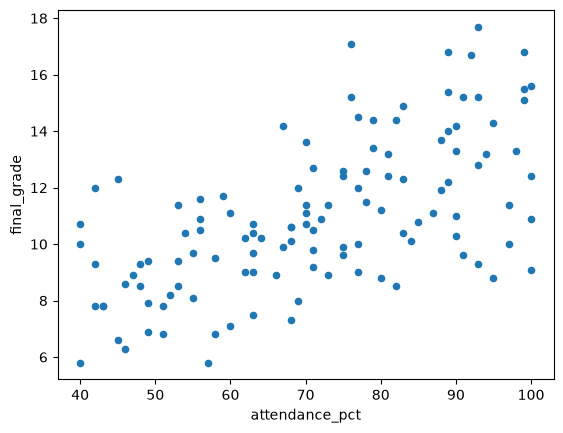

In [ ]:
# 1-Mean Final Grade :
print(df.loc[df["study_hours_week"] > 8, "final_grade"].mean().round(2))


# 2-Filling the missing 'sduty_hours_week values
m= df["study_hours_week"].median()
df["study_hours_week"] = df["study_hours_week"].fillna(m)
print(df.isna().sum())


# 3- Plot final_grade against attendance_pct
df.plot.scatter(x="attendance_pct",y="final_grade")


# 4-Calculations
p1= df.loc[df["attendance_pct"] >= 80, "passed"].mean()
p2= df["passed"].mean()
print(" Calcule results : ")
print(" P(passed|attendance>= 80%): ",round(p1, 3))
print(" P(passed): ", round(p2, 3))
print(" Independent:", np.isclose(p1,p2, atol=0.01))

## Before you submit

**What I learned / what confused me** (5 lines, in your own words — no AI tools for this cell):

1. How to use NumPy
2. Practiced working with Pandas on a sample of data
3. No confusions at the moment

Then commit and push this notebook to your course GitHub repository:

```bash
git add . && git commit -m "Lab: <name>" && git push
```
